 Imports & Setups

In [11]:
import json
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Step 1 - Automatic Data Download & Load

In [12]:
print("--- 1. DOWNLOADING & LOADING DATASETS ---")
dataset_path = kagglehub.dataset_download("tmdb/tmdb-movie-metadata")

movies_df = pd.read_csv(f"{dataset_path}/tmdb_5000_movies.csv")
credits_df = pd.read_csv(f"{dataset_path}/tmdb_5000_credits.csv")

# Merge datasets on unique movie ID
credits_df.rename(columns={"movie_id": "id"}, inplace=True)
df = movies_df.merge(credits_df[["id", "cast", "crew"]], on="id")
print(f"Merged Dataset Shape: {df.shape} ({df.shape[0]} rows, {df.shape[1]} features)\n")

--- 1. DOWNLOADING & LOADING DATASETS ---
Merged Dataset Shape: (4803, 22) (4803 rows, 22 features)



 Requirement (a) - Feature Engineering & Initial Data Understanding

In [13]:
print("--- REQUIREMENT (a): INITIAL DATA UNDERSTANDING (STATS) ---")

def get_json_count(json_str):
    try:
        return len(json.loads(json_str))
    except Exception:
        return 0

# Feature engineering: extract numeric counts from JSON strings
df["cast_size"] = df["cast"].apply(get_json_count)
df["crew_size"] = df["crew"].apply(get_json_count)
df["genres_count"] = df["genres"].apply(get_json_count)

# Predictor features (X) and Target variable (y)
num_features = [
    "budget",
    "popularity",
    "runtime",
    "vote_count",
    "vote_average",
    "cast_size",
    "crew_size",
    "genres_count",
]
target = "revenue"

analysis_df = df[num_features + [target]].copy()

# Descriptive Statistics
stats_summary = pd.DataFrame(
    {
        "Mean": analysis_df.mean(),
        "Median": analysis_df.median(),
        "Std Dev": analysis_df.std(),
    }
)
print("Central Tendency & Dispersion:")
print(stats_summary.round(2))
print("\n" + "=" * 60 + "\n")

# Covariance & Correlation Matrices
print("Covariance Matrix (Sample of Key Features):")
print(analysis_df[["budget", "popularity", "vote_count", target]].cov().round(2))
print("\n" + "=" * 60 + "\n")

corr_matrix = analysis_df.corr()
print("Correlation Matrix with Target (revenue):")
print(corr_matrix[target].sort_values(ascending=False).round(3))
print("\n" + "=" * 60 + "\n")

--- REQUIREMENT (a): INITIAL DATA UNDERSTANDING (STATS) ---
Central Tendency & Dispersion:
                     Mean       Median       Std Dev
budget        29045039.88  15000000.00  4.072239e+07
popularity          21.49        12.92  3.182000e+01
runtime            106.88       103.00  2.261000e+01
vote_count         690.22       235.00  1.234590e+03
vote_average         6.09         6.20  1.190000e+00
cast_size           22.12        16.00  1.958000e+01
crew_size           26.98        16.00  3.163000e+01
genres_count         2.53         2.00  1.120000e+00
revenue       82260638.65  19170001.00  1.628571e+08


Covariance Matrix (Sample of Key Features):
                  budget    popularity    vote_count       revenue
budget      1.658313e+15  6.548397e+08  2.982231e+10  4.846766e+15
popularity  6.548397e+08  1.012300e+03  3.056524e+04  3.340678e+09
vote_count  2.982231e+10  3.056524e+04  1.524202e+06  1.571267e+11
revenue     4.846766e+15  3.340678e+09  1.571267e+11  2.652244e+1

Requirement (b) - Preprocessing & Scaling

In [14]:
print("--- REQUIREMENT (b): PREPROCESSING ---")

# 1. Impute missing runtime values with median
analysis_df["runtime"] = analysis_df["runtime"].fillna(analysis_df["runtime"].median())

# 2. Filter unreleased / zero-revenue / unvoted movies to clean noisy data
clean_df = analysis_df[
    (analysis_df["revenue"] > 10000) & (analysis_df["budget"] > 10000)
].copy().reset_index(drop=True)
print(f"Cleaned dataset shape (valid budget & revenue): {clean_df.shape}")

# 3. Separate Features (X) and Target (y)
X = clean_df[num_features]
y = clean_df[target]

# 4. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("StandardScaler applied successfully to features.\n" + "=" * 60 + "\n")

--- REQUIREMENT (b): PREPROCESSING ---
Cleaned dataset shape (valid budget & revenue): (3203, 9)
StandardScaler applied successfully to features.



Requirement (c) - Model Training & Visualizations

--- REQUIREMENT (c): MODEL TRAINING & PLOTTING ---


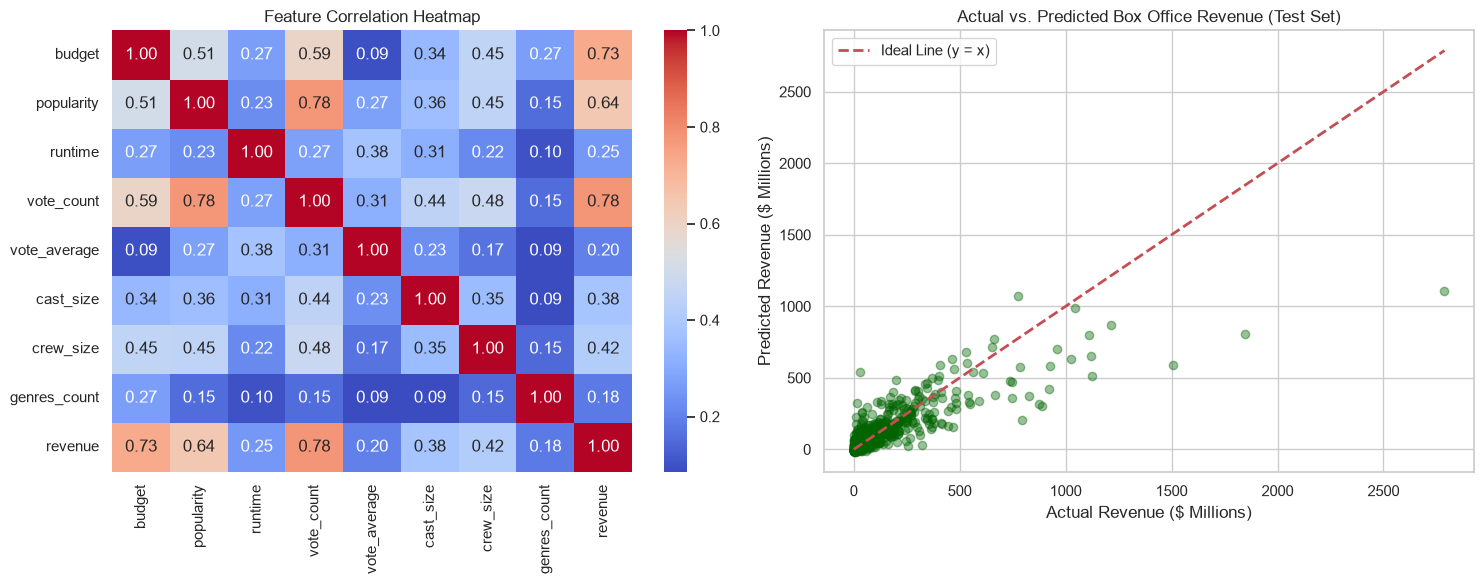

In [15]:
print("--- REQUIREMENT (c): MODEL TRAINING & PLOTTING ---")

model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Feature Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Feature Correlation Heatmap", fontsize=12)

# Plot 2: Actual vs. Predicted Box Office Revenue ($ Millions)
y_pred_test = model.predict(X_test_scaled)
axes[1].scatter(y_test / 1e6, y_pred_test / 1e6, alpha=0.4, color="darkgreen")
axes[1].plot(
    [y_test.min() / 1e6, y_test.max() / 1e6],
    [y_test.min() / 1e6, y_test.max() / 1e6],
    "r--",
    lw=2,
    label="Ideal Line (y = x)",
)
axes[1].set_xlabel("Actual Revenue ($ Millions)")
axes[1].set_ylabel("Predicted Revenue ($ Millions)")
axes[1].set_title("Actual vs. Predicted Box Office Revenue (Test Set)", fontsize=12)
axes[1].legend()

plt.tight_layout()
plt.show()

Requirement (d) - Model Evaluation Metrics

In [16]:
print("--- REQUIREMENT (d): EVALUATION METRICS ---")

y_pred_train = model.predict(X_train_scaled)

def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {
        "MSE ($)": mse,
        "RMSE ($)": rmse,
        "MAE ($)": mae,
        "R² Score": r2
    }

metrics_df = pd.DataFrame(
    {
        "Training Set": compute_metrics(y_train, y_pred_train),
        "Testing Set": compute_metrics(y_test, y_pred_test),
    }
)

print(metrics_df.round(2))
print("\n" + "=" * 60 + "\n")

--- REQUIREMENT (d): EVALUATION METRICS ---
          Training Set   Testing Set
MSE ($)   8.796567e+15  1.789101e+16
RMSE ($)  9.379002e+07  1.337573e+08
MAE ($)   5.677825e+07  6.519775e+07
R² Score  7.100000e-01  6.600000e-01




 Requirement (e) - Model Interpretation & Coefficients

In [17]:
print("--- REQUIREMENT (e): FINAL ANALYSIS & INTERPRETATION ---")

feature_weights = pd.DataFrame(
    {"Feature": num_features, "Coefficient ($)": model.coef_}
).sort_values(by="Coefficient ($)", ascending=False)

print("Standardized Coefficients (Dollar Impact per +1 Std Dev):")
print(feature_weights.to_string(index=False))

--- REQUIREMENT (e): FINAL ANALYSIS & INTERPRETATION ---
Standardized Coefficients (Dollar Impact per +1 Std Dev):
     Feature  Coefficient ($)
  vote_count     7.814016e+07
      budget     7.558801e+07
  popularity     2.034372e+07
   cast_size     3.559086e+06
vote_average     3.369657e+05
genres_count    -8.273497e+05
     runtime    -1.606469e+06
   crew_size    -6.387932e+06
